In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from optimizer import grid_search, strategy_compare

In [3]:
STRATEGIES = {
    "BuyHold": {"minimum_profit": np.inf},
    "Default": {},
    "Experimental1": {"buy_embargo": 90.0},
}

In [4]:
df_prices = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_prices.drop("DOGE", axis=1, inplace=True)
df_prices

,BTC,ETH,SOL,XRP,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.212025,1.111869,11.943166,0.175209,600.638428


# COMPARE

In [5]:
history_compare = strategy_compare(
    prices=df_prices,
    strategies=STRATEGIES,
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 4,
)

100%|██████████| 3/3 [02:18<00:00, 46.31s/it]


In [6]:
history_compare

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MA200_survival_days,RoAC,iteration
0,BuyHold,DOT,2752,0,775,2752,775,27,2.911988,2,-1728,0.000000,-14,1
1,BuyHold,XLM,2583,0,5180,2583,5180,25,0.129024,2,-6603,202.666667,4,1
2,BuyHold,SOL,2574,0,14322,2574,14322,58,33.918326,2,-11512,85.200000,178,1
3,BuyHold,LINK,2583,0,3966,2583,3966,46,9.828610,2,-4147,65.125000,10,1
4,BuyHold,ETH,2326,0,2471,2326,2471,86,1936.162129,1,-3167,0.000000,47,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,Experimental1,SOL,2455,11414,1484,282,12899,81,30.060871,11,-1968,147.000000,1557,100
2996,Experimental1,XLM,2831,4663,1678,814,6341,32,0.130729,4,-3270,204.666667,33,100
2997,Experimental1,XRP,2841,6347,458,275,6805,51,0.504905,7,-2948,122.333333,256,100
2998,Experimental1,XRP,2455,1665,1962,1695,3627,71,0.434640,5,-1118,73.750000,153,100


In [7]:
compare_res = history_compare.groupby("strategy").agg(
    RoAC=("RoAC", "mean"),
    MDD=("MDD", "mean"),
    Portfolio=("Portfolio", "mean"),
    Realized_cash=("Realized_cash", "mean"),
    Cash_spent=("Cash_spent", "mean"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_median=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

compare_res['Uncle'] = compare_res['MDD'] / compare_res['Total_value_mean']
compare_res['Profit_coef'] = compare_res['Total_value_mean'] / compare_res['Cash_spent']
compare_res.sort_values("RoAC", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC,MDD,Portfolio,Realized_cash,Cash_spent,Total_value_mean,Total_value_median,Total_value_low,Total_value_high,Uncle,Profit_coef
strategy,,,,,,,,,,,
Experimental1,391.24,-1497.66,1243.88,4415.37,2513.06,5659.69,4886.50,3685.25,6890.50,-0.26,2.25
Default,369.73,-1409.66,1183.44,4085.50,2383.81,5269.42,4662.00,3560.50,6529.25,-0.27,2.21
BuyHold,192.44,-12776.04,7295.47,0.00,2313.36,7295.47,3992.50,2433.00,7657.00,-1.75,3.15


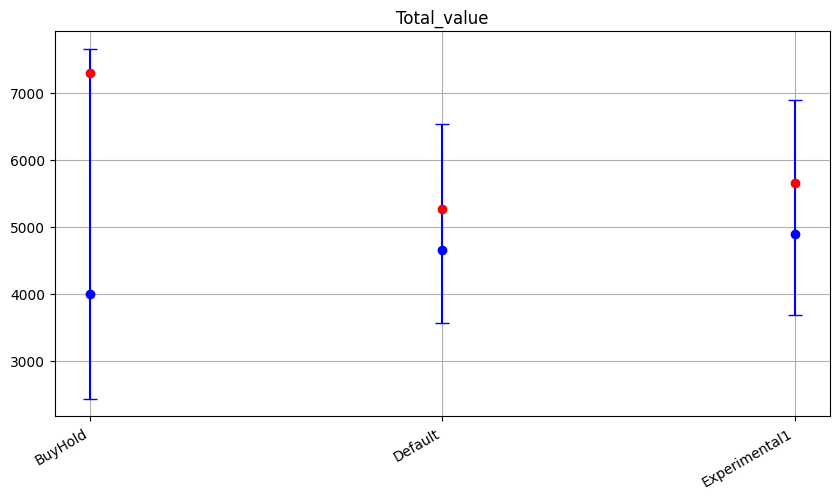

In [8]:
metric = "Total_value"

plt.figure(figsize=(10, 5))

median = compare_res[f"{metric}_median"]
mean = compare_res[f"{metric}_mean"]
low = compare_res[f"{metric}_low"]
high = compare_res[f"{metric}_high"]

plt.errorbar(
    median.index,
    median.values,
    yerr=[median - low, high - median],
    fmt="o",
    capsize=5,
    label="median",
    color="blue",
)
plt.errorbar(
    mean.index,
    mean.values,
    fmt="o",
    capsize=5,
    label="mean",
    color="red",
)
plt.title(metric)
plt.xticks(rotation=30, ha="right")
plt.grid()
plt.show()